# ECON 422: Macroeconomics & Machine Learning
## Learn the transformation, then forecast
**Key message:** fixed differencing imposes weights; learning estimates them. After transformation, classical models and ML can forecast what remains.

In [1]:
# Copy and paste from Quizzes '[Week12] (Nov9) Exercise'.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from statsmodels.tsa.arima.model import ARIMA
from sklearn.ensemble import RandomForestRegressor

plt.rcParams.update({"figure.figsize": (9, 3), "axes.spines.top": False,
"axes.spines.right": False, "font.size": 11})
def rmse(actual, forecast):
    return np.sqrt(np.mean((np.asarray(actual) - np.asarray(forecast))**2))
pd.set_option("display.max_columns", None)
# Build predictors in chronological order: yesterday, two periods ago, etc.
def lag_pairs(series, p):
    series = np.asarray(series)
    X = np.column_stack([series[p-j:len(series)-j] for j in range(1, p+1)])
    return X, series[p:]

### Problem 1 — Learn one weight
Predict today from yesterday and minimize squared error:
$$z_t=y_t-a y_{t-1},\qquad
\widehat a=\frac{\sum y_{t-1}y_t}{\sum y_{t-1}^2}.$$
For $10,11,10,12,11$, the answer is $472/465\approx1.015$. First differencing fixes $a=1$; learning estimates it. This tiny example illustrates fitting, not a unit-root test.

,a,Total squared error
0,0.8,28.4
1,1.0,7.0
2,1.2,22.8


Learned a = 1.015054; transformation: z = today - 1.015 × yesterday


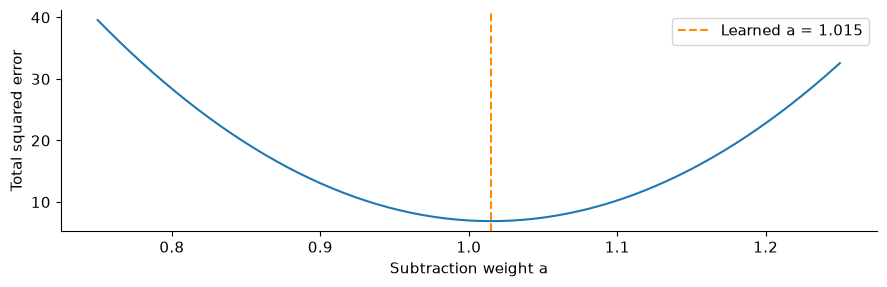

In [2]:
# Create four pairs of yesterday/today observations.
toy = np.array([10, 11, 10, 12, 11], dtype=float)
x, target = toy[:-1], toy[1:]
# Estimate the subtraction weight by least squares.
a_toy = (x @ target) / (x @ x)
candidates = [0.8, 1.0, 1.2]
display(pd.DataFrame({"a": candidates,
    "Total squared error": [np.sum((target-a*x)**2) for a in candidates]}))
print(f"Learned a = {a_toy:.6f}; transformation: z = today - {a_toy:.3f} × yesterday")
# Plot training error to see which weight fits best.
grid = np.linspace(0.75, 1.25, 200)
plt.plot(grid, [np.sum((target-a*x)**2) for a in grid])
plt.axvline(a_toy, color="darkorange", linestyle="--", label=f"Learned a = {a_toy:.3f}")
plt.xlabel("Subtraction weight a"); plt.ylabel("Total squared error")
plt.legend(); plt.tight_layout(); plt.show()

### Problem 2 — Second differencing: correct in A, misspecified in B
Compare **the same second-difference filter** with learned weights in two AR(2) models:

| Case | True model | Second differencing + white noise | Learned filter weights |
|---|---|---|---|
| **A: correctly specified (the classical time series)** | $y_t=2y_{t-1}-y_{t-2}+\varepsilon_t$ | $\Delta^2y_t=\varepsilon_t$ | Estimates $(2,-1)$ |
| **B: misspecified (the classical time series)** | $y_t=0.7y_{t-1}+0.3y_{t-2}+\varepsilon_t$ | $\Delta^2y_t=-1.3\Delta y_{t-1}+\varepsilon_t$ | Estimates $(0.7,0.3)$ |

**Why $(2,-1)$?**
$$\Delta^2y_t=(y_t-y_{t-1})-(y_{t-1}-y_{t-2})
=y_t-2y_{t-1}+y_{t-2}.$$
Matching $z_t=y_t-a_1y_{t-1}-a_2y_{t-2}$ gives $a_1=2$, $a_2=-1$.

**Evaluation:** 100 simulated series per case; 400 training and 200 test observations each. Learn weights only on training data. Forecast the next $z$ as zero for both methods, so $\widehat y_t=a_1y_{t-1}+a_2y_{t-2}$. Use already-observed past levels for rolling one-step test forecasts. The charts report pooled level-forecast RMSE; the shock standard deviation is 1.

Case A: true weights [ 2. -1.]; mean learned weights [ 1.993 -0.993]
Case B: true weights [0.7 0.3]; mean learned weights [0.699 0.294]


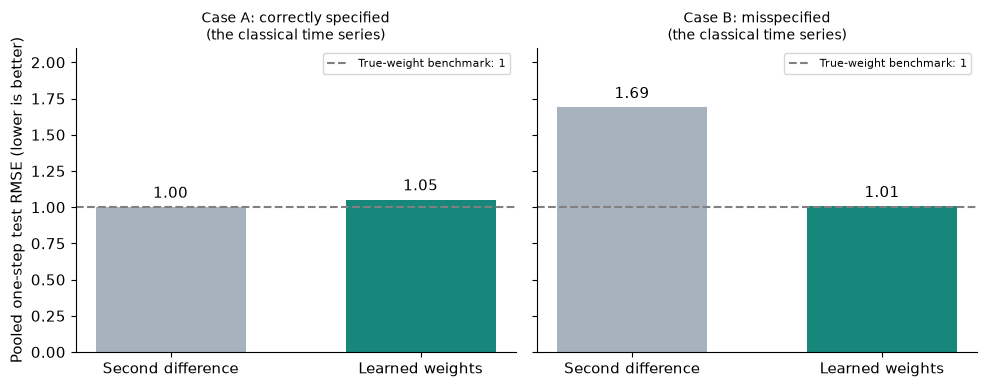

,Case,Method,Test RMSE
0,A,Second difference,1.002
1,A,Learned weights,1.053
2,B,Second difference,1.690
3,B,Learned weights,1.007


In [3]:
# Specify the two AR(2) data-generating processes.
case_weights = {"A": np.array([2., -1.]), "B": np.array([0.7, 0.3])}
fixed_weights = np.array([2., -1.])  # Second differencing in BOTH cases.
repetitions, n_train, n_test = 100, 400, 200
rng = np.random.default_rng(422)
losses = {(case, method): [] for case in case_weights
          for method in ["Second difference", "Learned weights"]}
estimates = {case: [] for case in case_weights}

# Repeat the experiment instead of selecting one favorable sample.
for _ in range(repetitions):
    shocks = rng.normal(size=n_train+n_test)
    for case, true_weights in case_weights.items():
        y = np.zeros(len(shocks))
        for t in range(2, len(y)):
            y[t] = true_weights @ y[t-2:t][::-1] + shocks[t]
        # Fit two subtraction weights using only the training segment.
        X_train, target = lag_pairs(y[:n_train], 2)
        learned = np.linalg.lstsq(X_train, target, rcond=None)[0]
        estimates[case].append(learned)
        # Each forecast uses the two levels observed before that test date.
        X_test = np.column_stack([y[n_train-1:-1], y[n_train-2:-2]])
        for method, weights in [("Second difference", fixed_weights), ("Learned weights", learned)]:
            error = y[n_train:] - X_test @ weights
            losses[case, method].extend(error**2)

# Put Cases A and B in separate panels; do not mix in first differencing.
rows = []
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, case in zip(axes, case_weights):
    methods = ["Second difference", "Learned weights"]
    values = [np.sqrt(np.mean(losses[case, method])) for method in methods]
    status = "correctly specified" if case == "A" else "misspecified"
    bars = ax.bar(methods, values, color=["#A7B2BC", "#16877A"], width=0.6)
    ax.bar_label(bars, fmt="%.2f", padding=4)
    ax.axhline(1., color="gray", linestyle="--", label="True-weight benchmark: 1")
    ax.set_title(f"Case {case}: {status}\n(the classical time series)", fontsize=10)
    ax.set_ylim(0, 2.1); ax.legend(fontsize=8)
    for method, value in zip(methods, values):
        rows.append({"Case": case, "Method": method, "Test RMSE": value})
    print(f"Case {case}: true weights {case_weights[case]}; mean learned weights "
          f"{np.mean(estimates[case], axis=0).round(3)}")
axes[0].set_ylabel("Pooled one-step test RMSE (lower is better)")
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).round(3))

**Takeaway:** in A, second differencing already matches the true filter; learning cannot improve its population forecast. In B, the second-difference-plus-white-noise model omits predictable dependence, which learned weights can remove. “Misspecified” refers to that classical forecasting model—not to the learned-weight bar. Both learned AR(2) classes contain the true DGP here, though their estimates have sampling error. Classical ARMA after differencing could also model the remaining dependence.

### Problem 3 — A simple reconstruction example
For the simple one-lag transformation,
$$z_t=y_t-a y_{t-1}\quad\Longrightarrow\quad
\boxed{\widehat y_{t+1}=a y_t+\widehat z_{t+1}.}$$

**Example:** $a=0.8$, yesterday's value is 10, today's is 9. Suppose the ARMA forecast is $\widehat z_{t+1}=0.4z_t+0.2\widehat\varepsilon_t$, with latest estimated shock $0.5$. The next cell shows all three steps. These numbers are illustrative.

**This is a standalone one-lag illustration.** Problem 4 selects the number of lags by time-ordered validation, learns their weights, and then reverses the transformation.

In [4]:
# 1. Transform today's observed level.
a = 0.8
y_yesterday, y_today = 10.0, 9.0
z_today = y_today - a*y_yesterday

# 2. Forecast z using illustrative fitted ARMA coefficients.
z_forecast = 0.4*z_today + 0.2*0.5

# 3. Add back the weighted last level to obtain the forecast of y.
y_forecast = a*y_today + z_forecast

display(pd.DataFrame({
    "Step": ["Transform", "Forecast z", "Reconstruct y"],
    "Calculation": ["9 − 0.8 × 10", "0.4 × 1 + 0.2 × 0.5", "0.8 × 9 + 0.5"],
    "Result": [z_today, z_forecast, y_forecast]
}).round(2))

,Step,Calculation,Result
0,Transform,9 − 0.8 × 10,1.0
1,Forecast z,0.4 × 1 + 0.2 × 0.5,0.5
2,Reconstruct y,0.8 × 9 + 0.5,7.7


### Problem 4 — Real FRED data: select $p$, learn weights, forecast
Default: **INDPRO (Industrial Production: Total Index)**, monthly and seasonally adjusted, from January 1985 through December 2025. Change the series ID to try another complete monthly series.

1. Download the original levels $y_t$; **do not choose $d$ or difference first**.
2. For each candidate $p$, estimate lag weights directly from training levels:
$$z_t=y_t-\sum_{j=1}^p\widehat a_jy_{t-j}.$$
3. Forecast $z$ using each ML method plus ARMA. Select the method and $p$ by three time-ordered, 24-month validation forecasts, scored in original levels.
4. Refit on the training sample, evaluate on the last 24 months, then refit on all downloaded observations for future forecasts.

**Learning the transformation:** first differencing is the special weight choice $(1)$, and second differencing is $(2,-1)$. Here the weights are unrestricted: the machine learns a more general filter rather than selecting an exact integer $d$. Prediction-error minimization does not guarantee that $z$ is stationary. Filter diagnostics below describe its resemblance to differencing; they do not certify stationarity. ARMA for the remaining component is a modeling assumption to assess, especially with other series.

**$p$ now counts lags of the original levels.** Linear regression estimates their weights with an intercept, but the intercept is retained in $z$ for the downstream models to learn. ML uses known calendar features; those need not improve an already seasonally adjusted series.

**Setup:** get a key at [FRED API keys](https://fred.stlouisfed.org/docs/api/api_key.html). Enter it at the hidden prompt, or set the `FRED_API_KEY` environment variable. Do not paste it into a saved cell.

Sources: [INDPRO](https://fred.stlouisfed.org/series/INDPRO) · [API observations documentation](https://fred.stlouisfed.org/docs/api/fred/series_observations.html). The download uses currently revised historical values, so this is a historical backtest, not a real-time vintage evaluation.



**Connection troubleshooting:** the download supplements Python’s trusted certificates with `certifi` when installed and reports certificate, timeout, and DNS errors separately. If the API cannot be reached, it tries FRED’s public CSV endpoint and announces the source. Set `DATA_SOURCE = "public_csv"` to use that endpoint directly without a key. For a certificate error, run `%pip install --upgrade certifi` in a new cell, restart the kernel, and run again. Certificate verification remains enabled. See [certifi](https://github.com/certifi/python-certifi) and [Python HTTPS contexts](https://docs.python.org/3/library/urllib.request.html).

**ML comparison:** Random Forest, Extra Trees, Gradient Boosting, and Ridge regression. Each uses the same calendar features and validation windows, but selects its own $p$. We select the final method–$p$ pair by validation RMSE, before inspecting the test period. Other ML settings are fixed for simplicity. Linear regression still estimates the AR weights; the methods below predict the remaining $z$.

*Saved outputs were checked using the equivalent public FRED data download. Rerunning this notebook downloads through the API using your own key.*

Data source: FRED API.
Downloaded 492 monthly observations of INDPRO.
Training ends 2023-12; test: 2024-01 to 2025-12.


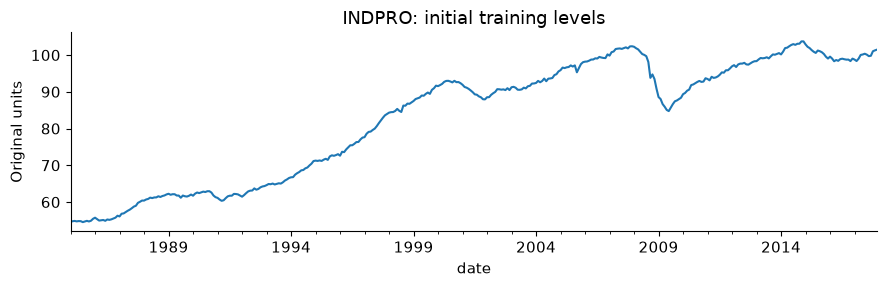

In [5]:
import os, json, ssl, socket, io
from getpass import getpass
from urllib.parse import urlencode
from urllib.request import urlopen
from urllib.error import HTTPError, URLError
from sklearn.linear_model import LinearRegression
from scipy.stats import gaussian_kde

SERIES_ID = "INDPRO"
START_DATE, END_DATE = "1985-01-01", "2025-12-31"
steps, draws = 24, 400     # Forecast months; simulated paths for bands.
p_candidates = [1, 2, 3, 4, 6, 12]
DATA_SOURCE = "api"  # Or "public_csv" to download from FRED without a key.

def connection_reason(error):
    # Report useful categories without exposing request URLs or API keys.
    reason = getattr(error, "reason", error)
    if isinstance(reason, ssl.SSLCertVerificationError):
        return "Python could not verify the HTTPS certificate"
    if isinstance(reason, (TimeoutError, socket.timeout)):
        return "the connection timed out"
    if isinstance(reason, socket.gaierror):
        return "DNS could not resolve the FRED server"
    if isinstance(error, HTTPError):
        return f"the server returned HTTP {error.code}"
    return f"a connection error occurred ({type(reason).__name__})"

def download_fred(series_id, start, end):
    # Keep HTTPS verification enabled; supplement system roots if certifi is installed.
    context = ssl.create_default_context()
    try:
        import certifi
        context.load_verify_locations(cafile=certifi.where())
    except ImportError:
        pass  # System certificates still work on correctly configured Python installs.
    table = None
    if DATA_SOURCE not in ("api", "public_csv"):
        raise ValueError('DATA_SOURCE must be "api" or "public_csv".')
    if DATA_SOURCE == "api":
        key = (os.getenv("FRED_API_KEY") or getpass("FRED API key (hidden): ")).strip()
        if not key:
            raise ValueError('Enter your API key, or set DATA_SOURCE = "public_csv".')
        query = urlencode({"series_id": series_id, "api_key": key,
                           "file_type": "json", "observation_start": start,
                           "observation_end": end, "sort_order": "asc"})
        try:
            with urlopen("https://api.stlouisfed.org/fred/series/observations?" + query,
                         timeout=30, context=context) as response:
                payload = json.load(response)
            table = pd.DataFrame(payload.get("observations", []))
            if table.empty:
                raise ValueError("FRED returned no observations; check the series and dates.")
            print("Data source: FRED API.")
        except HTTPError as error:
            # An HTTP rejection differs from a failure to connect.
            raise RuntimeError(f"FRED responded with HTTP {error.code}. Check the key, "
                               'series ID, or rate limit. You can also set DATA_SOURCE = "public_csv".') from None
        except (URLError, TimeoutError, ssl.SSLError) as error:
            print("API connection failed: " + connection_reason(error) + ".")
            print("Trying FRED's public CSV download (no key is sent).")
    if table is None:
        query = urlencode({"id": series_id, "cosd": start, "coed": end})
        try:
            with urlopen("https://fred.stlouisfed.org/graph/fredgraph.csv?" + query,
                         timeout=30, context=context) as response:
                csv = pd.read_csv(io.BytesIO(response.read()))
        except (URLError, TimeoutError, ssl.SSLError) as error:
            raise RuntimeError("Public FRED download also failed: " + connection_reason(error) +
                ". If this is a certificate error, run %pip install --upgrade certifi in a new cell "
                "and restart the kernel. Otherwise check network/VPN/proxy access to FRED.") from None
        if series_id not in csv or len(csv.columns) != 2:
            raise ValueError("Unexpected FRED CSV format; check the series ID.")
        table = csv.rename(columns={csv.columns[0]: "date", series_id: "value"})
        print("Data source: public FRED CSV (not the authenticated API).")
    values = pd.to_numeric(table["value"], errors="coerce").to_numpy()
    series = pd.Series(values, index=pd.to_datetime(table["date"]), name=series_id).sort_index()
    series = series.loc[start:end]
    if series.empty:
        raise ValueError("No observations in the requested date range.")
    # Refuse gaps rather than dropping months or filling using future values.
    expected = pd.date_range(series.index[0], series.index[-1], freq="MS")
    if not series.index.equals(expected) or series.isna().any():
        raise ValueError("Use a complete monthly series dated at month start; missing months need review.")
    return series

y_series = download_fred(SERIES_ID, START_DATE, END_DATE)
y_fc = y_series.to_numpy()
cutoff = len(y_fc) - steps
origins = [cutoff-3*steps, cutoff-2*steps, cutoff-steps]
if origins[0] < max(120, max(p_candidates)+30):
    raise ValueError("Choose a longer history: at least 18 years for these settings.")
train_fc, test_fc = y_fc[:cutoff], y_fc[cutoff:]
# Include dates beyond the downloaded sample for the final future forecast.
all_dates = pd.date_range(y_series.index[0], periods=len(y_series)+steps, freq="MS")
month = all_dates.month.to_numpy()
# Same annual and semiannual features for every learner.
calendar = np.column_stack([np.sin(2*np.pi*month/12), np.cos(2*np.pi*month/12),
                            np.sin(4*np.pi*month/12), np.cos(4*np.pi*month/12)])
print(f"Downloaded {len(y_series)} monthly observations of {SERIES_ID}.")
print(f"Training ends {y_series.index[cutoff-1]:%Y-%m}; test: "
      f"{y_series.index[cutoff]:%Y-%m} to {y_series.index[-1]:%Y-%m}.")
# Inspect the initial training levels without a preliminary transformation.
y_series.iloc[:origins[0]].plot(title=f"{SERIES_ID}: initial training levels")
plt.ylabel("Original units"); plt.tight_layout(); plt.show()


#### Fit and reconstruct functions
Each call uses only the supplied history. Calendar features for future dates are known in advance.

In [6]:
# 1. Learn the transformation directly from original training levels.
def learn_filter(y_history, p):
    x = np.asarray(y_history)  # No preset differencing.
    X, target = lag_pairs(x, p)
    learner = LinearRegression().fit(X, target)
    weights = learner.coef_
    z = target - X @ weights  # Keep the mean for the downstream models.
    return x, weights, z

# 2. Recover levels directly by adding back the learned lag terms.
def reconstruct(z_forecasts, y_history, weights):
    paths = np.atleast_2d(z_forecasts)
    p = len(weights)
    history = np.tile(y_history[-p:], (len(paths), 1))
    y_future = np.empty_like(paths)
    for h in range(paths.shape[1]):
        y_future[:, h] = history[:, -p:][:, ::-1] @ weights + paths[:, h]
        history = np.column_stack([history, y_future[:, h]])
    return y_future

# 3. Fit ARMA to z (or to the ML residuals). Simulate only for the final plots.
def arma_forecast(series, n_draws=0):
    location, scale = np.mean(series), max(np.std(series), 1e-8)
    fitted = ARIMA((series-location)/scale, order=(1, 0, 1), trend="c").fit(
        method_kwargs={"maxiter": 1000, "method": "powell"})
    if not fitted.mle_retvals.get("converged", True):
        raise RuntimeError("ARMA did not converge; inspect the fit.")
    mean = location + scale*np.asarray(fitted.forecast(steps))
    paths = None
    if n_draws:
        paths = location + scale*np.asarray(fitted.simulate(
            nsimulations=steps, repetitions=n_draws, anchor="end",
            rng=np.random.default_rng(2026))).reshape(steps, n_draws).T
    return mean, paths

from sklearn.base import clone
from sklearn.ensemble import ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ml_models = {
    "Random Forest": RandomForestRegressor(n_estimators=150, min_samples_leaf=5,
                                           random_state=422, n_jobs=1),
    "Extra Trees": ExtraTreesRegressor(n_estimators=150, min_samples_leaf=5,
                                       random_state=422, n_jobs=1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, max_depth=2,
                                                   learning_rate=0.05, random_state=422),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
}

# Clone and refit every component using only this forecast origin's history.
def hybrid_forecast(y_history, p, method, n_draws=0):
    end = len(y_history)
    x, weights, z = learn_filter(y_history, p)
    ml = clone(ml_models[method])
    ml.fit(calendar[p:end], z)
    residuals = z - ml.predict(calendar[p:end])
    ml_mean = ml.predict(calendar[end:end+steps])
    residual_mean, residual_paths = arma_forecast(residuals, n_draws)
    forecast = reconstruct(ml_mean + residual_mean, x, weights)[0]
    paths = None if n_draws == 0 else reconstruct(
        ml_mean[None, :] + residual_paths, x, weights)
    return forecast, paths, weights


#### Select $p$ for each method, then select the final method
Every candidate uses the same three expanding-window, 24-month validation periods. The final test is excluded from all choices.

Validating Random Forest...


c:\Users\mbadi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\mbadi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
c:\Users\mbadi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\mbadi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. 

Validating Extra Trees...


c:\Users\mbadi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\mbadi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
c:\Users\mbadi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\mbadi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. 

Validating Gradient Boosting...


c:\Users\mbadi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\mbadi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
c:\Users\mbadi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\mbadi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. 

Validating Ridge...


c:\Users\mbadi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\mbadi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
c:\Users\mbadi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\mbadi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. 

Best lag order for each ML method:


,ML method,p,RMSE 2018-01–2019-12,RMSE 2020-01–2021-12,RMSE 2022-01–2023-12,Validation RMSE
0,Random Forest,6,1.011,5.675,0.649,3.349
1,Extra Trees,6,1.009,5.673,0.668,3.349
2,Gradient Boosting,6,1.021,5.706,0.648,3.368
3,Ridge,6,1.042,5.750,0.657,3.395


Selected by validation: Random Forest, p=6.


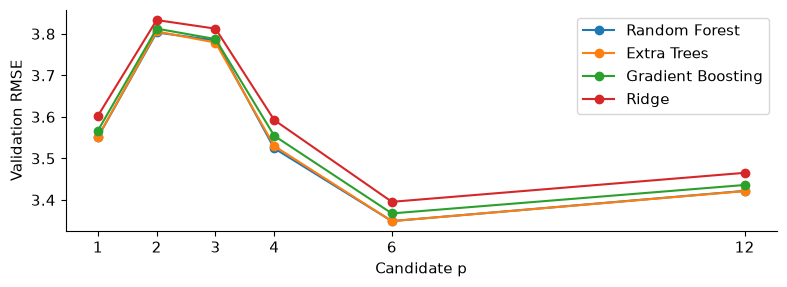

In [7]:
validation_rows = []
for method in ml_models:
    print(f"Validating {method}...")
    for p in p_candidates:
        squared_errors = []
        row = {"ML method": method, "p": p}
        for origin in origins:
            prediction = hybrid_forecast(train_fc[:origin], p, method)[0]
            actual = train_fc[origin:origin+steps]
            squared_errors.extend((actual-prediction)**2)
            row[f"RMSE {y_series.index[origin]:%Y-%m}–{y_series.index[origin+steps-1]:%Y-%m}"] = rmse(actual, prediction)
        row["Validation RMSE"] = np.sqrt(np.mean(squared_errors))
        validation_rows.append(row)
validation = pd.DataFrame(validation_rows).sort_values(
    ["Validation RMSE", "p", "ML method"]).reset_index(drop=True)
selected = validation.drop_duplicates("ML method").reset_index(drop=True)
best_method = selected.iloc[0]["ML method"]
best_p = int(selected.iloc[0]["p"])
print("Best lag order for each ML method:")
display(selected.round(3))
print(f"Selected by validation: {best_method}, p={best_p}.")
fig, ax = plt.subplots(figsize=(8, 3))
for method, rows in validation.groupby("ML method", sort=False):
    rows = rows.sort_values("p")
    ax.plot(rows["p"], rows["Validation RMSE"], "o-", label=method)
ax.set_xticks(p_candidates); ax.set_xlabel("Candidate p"); ax.set_ylabel("Validation RMSE")
ax.legend(); plt.tight_layout(); plt.show()


#### Refit and reconstruct levels
Invert the learned transformation directly:
$$\boxed{\widehat y_{T+h}=\sum_{j=1}^p\widehat a_j\widehat y_{T+h-j}+\widehat z_{T+h}.}$$
Use observed levels for dates through $T$, then recursively use predicted levels. There is **no cumulative-sum step** and no manually chosen $d$.

For interpretation, write $A(L)=1-\sum_j\widehat a_jL^j$. A first-difference factor requires $A(1)=1-\sum_j\widehat a_j=0$. A double factor additionally requires $A'(1)=-\sum_jj\widehat a_j=0$. We report these quantities without rounding them into an integer differencing order. Small values are descriptive, not a unit-root test.

**Trend labels:** “Trend (learned)” refers to the level path generated by the learned lag dynamics and the forecast mean of $z$; no separate deterministic trend is fitted. Each hybrid uses its own validation-selected $p$.

c:\Users\mbadi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\representation.py:374: FutureWarning: Unknown keyword arguments: dict_keys(['rng']).Passing unknown keyword arguments will raise a TypeError beginning in version 0.15.
  warnings.warn(msg, FutureWarning)
c:\Users\mbadi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\representation.py:374: FutureWarning: Unknown keyword arguments: dict_keys(['rng']).Passing unknown keyword arguments will raise a TypeError beginning in version 0.15.
  warnings.warn(msg, FutureWarning)
c:\Users\mbadi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\representation.py:374: FutureWarning: Unknown keyword arguments: dict_keys(['rng']).Passing unknown keyword arguments will raise a TypeError beginning in version 0.15.
  warnings.warn(msg, FutureWarning)
c:\Users\mbadi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa

,ML method,Selected p,Lag,AR weight
0,Random Forest,6,1,1.2320
1,Random Forest,6,2,-0.3916
2,Random Forest,6,3,0.1686
3,Random Forest,6,4,0.0189
4,Random Forest,6,5,0.0037
5,Random Forest,6,6,-0.0361
6,Extra Trees,6,1,1.2320
7,Extra Trees,6,2,-0.3916
8,Extra Trees,6,3,0.1686
9,Extra Trees,6,4,0.0189


,ML method,p,Sum of weights,A(1),A prime(1)
0,Random Forest,6,0.995403,0.004597,-0.831855
1,Extra Trees,6,0.995403,0.004597,-0.831855
2,Gradient Boosting,6,0.995403,0.004597,-0.831855
3,Ridge,6,0.995403,0.004597,-0.831855


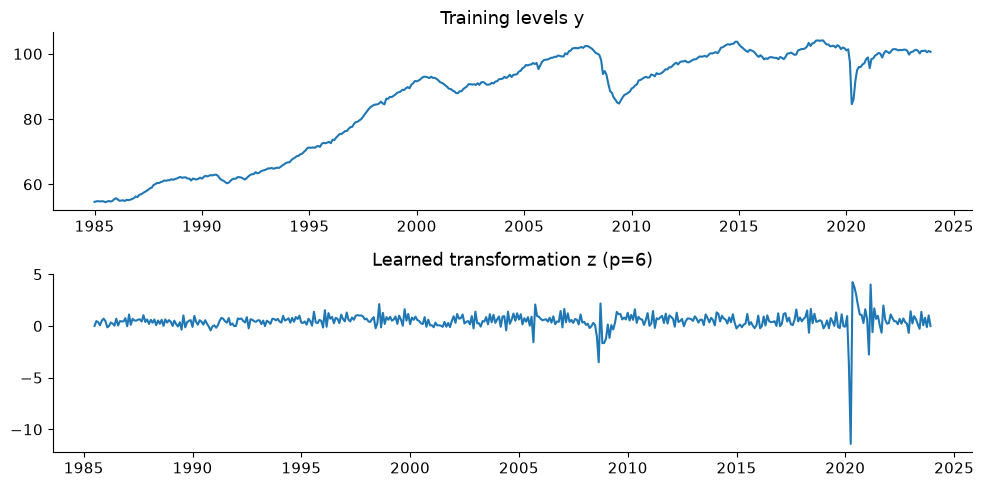

In [8]:
level_means, level_paths, chosen_p, weight_rows = {}, {}, {}, []
for row in selected.to_dict("records"):
    method, p = row["ML method"], int(row["p"])
    mean, paths, weights = hybrid_forecast(train_fc, p, method, draws)
    name = f"Trend (learned) + {method} + ARMA"
    level_means[name], level_paths[name], chosen_p[name] = mean, paths, p
    for lag, weight in enumerate(weights, 1):
        weight_rows.append({"ML method": method, "Selected p": p,
                            "Lag": lag, "AR weight": weight})
display(pd.DataFrame(weight_rows).round(4))

# Describe the learned filters; these are not formal unit-root tests.
filter_rows = []
for row in selected.to_dict("records"):
    p = int(row["p"])
    _, weights, z = learn_filter(train_fc, p)
    filter_rows.append({"ML method": row["ML method"], "p": p,
                        "Sum of weights": weights.sum(),
                        "A(1)": 1-weights.sum(),
                        "A prime(1)": -np.arange(1,p+1) @ weights})
display(pd.DataFrame(filter_rows).round(6))
_, selected_weights, selected_z = learn_filter(train_fc, best_p)
fig, axes = plt.subplots(2, 1, figsize=(10, 5))
axes[0].plot(y_series.index[:cutoff], train_fc)
axes[0].set_title("Training levels y")
axes[1].plot(y_series.index[best_p:cutoff], selected_z)
axes[1].set_title(f"Learned transformation z (p={best_p})")
plt.tight_layout(); plt.show()


#### Compare the four hybrids on the untouched final 24 months
Each uses its validation-selected lag order. The last-value benchmark is also reported. Test scores do not change the selected final method.

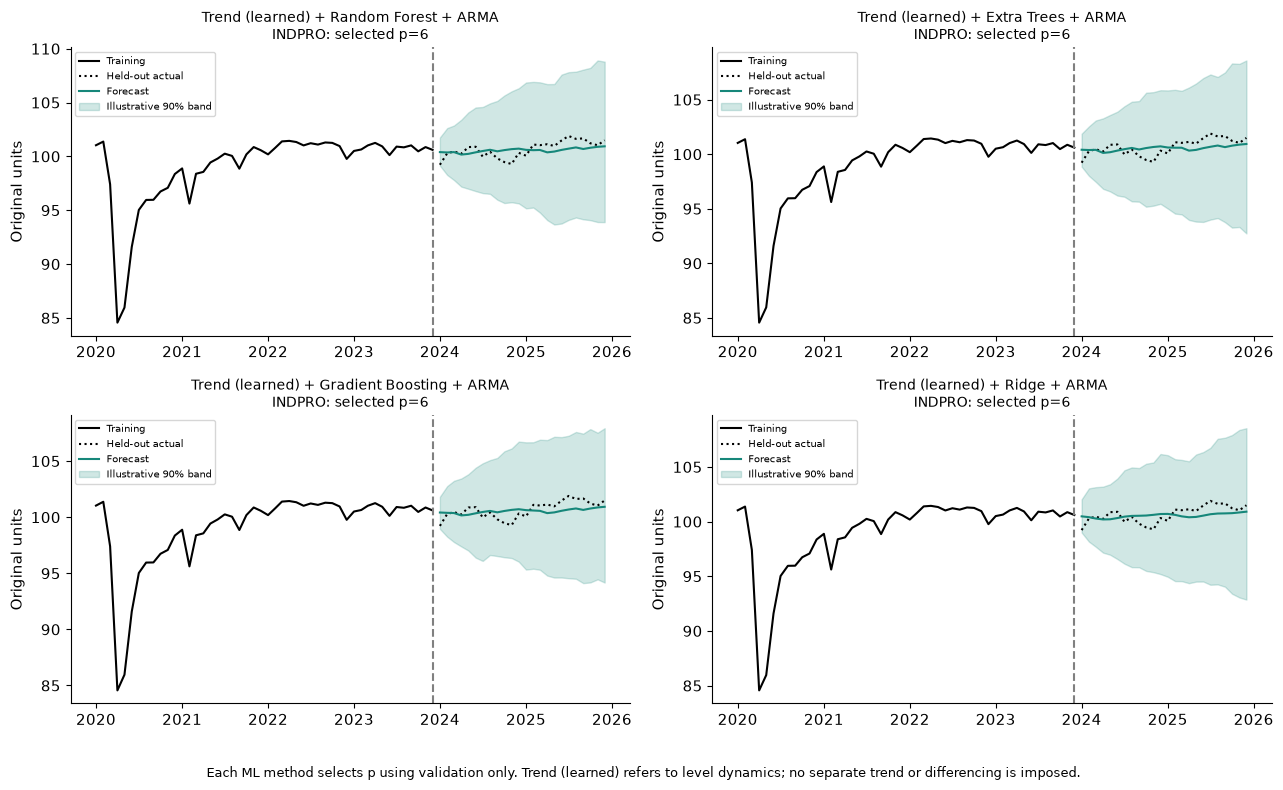

,Model,24-month test RMSE
0,Trend (learned) + Random Forest + ARMA,0.706
1,Trend (learned) + Extra Trees + ARMA,0.719
2,Trend (learned) + Gradient Boosting + ARMA,0.715
3,Trend (learned) + Ridge + ARMA,0.723
4,Last-value benchmark,0.751


,Actual,Trend (learned) + Random Forest + ARMA,Trend (learned) + Extra Trees + ARMA,Trend (learned) + Gradient Boosting + ARMA,Trend (learned) + Ridge + ARMA
date,,,,,
2024-01-01,99.222,100.397,100.410,100.418,100.479
2024-02-01,100.285,100.363,100.383,100.388,100.405
2024-03-01,100.458,100.397,100.400,100.369,100.281
2024-04-01,100.243,100.166,100.119,100.158,100.197
2024-05-01,100.863,100.234,100.182,100.212,100.212
2024-06-01,100.894,100.376,100.332,100.347,100.325
2024-07-01,99.976,100.499,100.463,100.466,100.453
2024-08-01,100.431,100.613,100.574,100.559,100.521
2024-09-01,99.808,100.470,100.433,100.433,100.534


In [9]:
test_dates = y_series.index[cutoff:]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
score_rows = []
for ax, (name, paths) in zip(axes.flat, level_paths.items()):
    mean = level_means[name]
    lower, upper = np.quantile(paths, [0.05, 0.95], axis=0)
    ax.plot(y_series.index[cutoff-48:cutoff], train_fc[-48:], color="black", label="Training")
    ax.plot(test_dates, test_fc, "k:", label="Held-out actual")
    ax.plot(test_dates, mean, color="#16877A", label="Forecast")
    ax.fill_between(test_dates, lower, upper, color="#16877A", alpha=0.2, label="Illustrative 90% band")
    ax.axvline(y_series.index[cutoff-1], color="gray", linestyle="--")
    ax.set_title(f"{name}\n{SERIES_ID}: selected p={chosen_p[name]}", fontsize=10)
    ax.set_ylabel("Original units"); ax.legend(fontsize=7)
    score_rows.append({"Model": name, "24-month test RMSE": rmse(test_fc, mean)})
score_rows.append({"Model": "Last-value benchmark", "24-month test RMSE": rmse(
    test_fc, np.repeat(train_fc[-1], steps))})
fig.text(0.5, 0.02, "Each ML method selects p using validation only. "
         "Trend (learned) refers to level dynamics; no separate trend or differencing is imposed.", ha="center", fontsize=9)
plt.tight_layout(rect=[0, 0.06, 1, 1]); plt.show()
display(pd.DataFrame(score_rows).round(3))
display(pd.DataFrame({"Actual": test_fc, **level_means}, index=test_dates).round(3))


**Interpretation:** compare forecast performance with the last-value benchmark. The learned filter may approximate differencing, but this code does not estimate a certified integer $d$ or guarantee stationarity. Bands condition on fitted models and omit method, lag-order, and parameter uncertainty. Revised FRED values make this a historical backtest rather than a real-time vintage evaluation.

#### Forecast with the validation-selected method
Keep the selected method and $p$, refit on all downloaded observations, and forecast the next 24 months. This starts after the downloaded sample, not necessarily today. Test performance does not select the final model.

c:\Users\mbadi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\representation.py:374: FutureWarning: Unknown keyword arguments: dict_keys(['rng']).Passing unknown keyword arguments will raise a TypeError beginning in version 0.15.
  warnings.warn(msg, FutureWarning)


,Lag,Weights refitted on all data
0,1,1.2191
1,2,-0.3741
2,3,0.1658
3,4,0.0119
4,5,0.0052
5,6,-0.0324


,Hybrid forecast,Lower 90%,Upper 90%
2026-01-01,101.457,100.186,102.772
2026-02-01,101.427,99.242,103.795
2026-03-01,101.398,98.713,104.132
2026-04-01,101.180,98.211,104.187
2026-05-01,101.283,97.894,104.549
2026-06-01,101.448,97.834,105.205
2026-07-01,101.538,97.563,105.762
2026-08-01,101.642,97.294,106.038
2026-09-01,101.485,96.553,106.162
2026-10-01,101.575,96.626,106.439


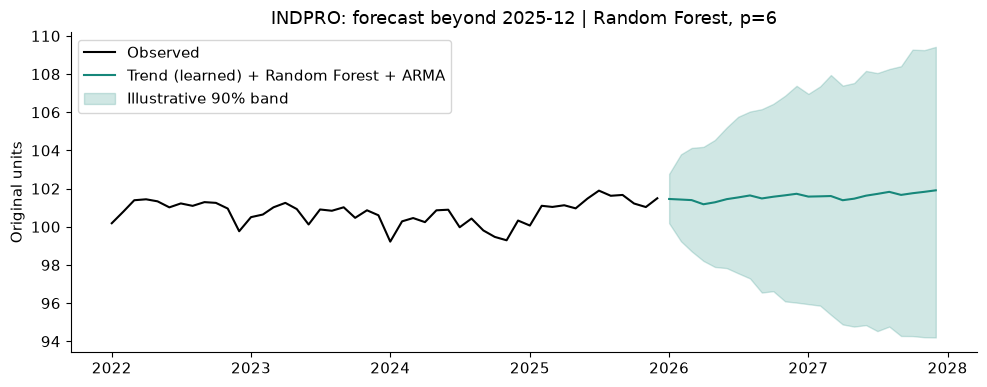

In [10]:
future_mean, future_paths, future_weights = hybrid_forecast(y_fc, best_p, best_method, draws)
future_dates = all_dates[len(y_fc):len(y_fc)+steps]
lower, upper = np.quantile(future_paths, [0.05, 0.95], axis=0)
future_table = pd.DataFrame({"Hybrid forecast": future_mean,
                             "Lower 90%": lower, "Upper 90%": upper}, index=future_dates)
display(pd.DataFrame({"Lag": np.arange(1, best_p+1),
                      "Weights refitted on all data": future_weights}).round(4))
display(future_table.round(3))
plt.figure(figsize=(10, 4))
plt.plot(y_series.index[-48:], y_fc[-48:], color="black", label="Observed")
plt.plot(future_dates, future_mean, color="#16877A", label=f"Trend (learned) + {best_method} + ARMA")
plt.fill_between(future_dates, lower, upper, color="#16877A", alpha=0.2,
                 label="Illustrative 90% band")
plt.title(f"{SERIES_ID}: forecast beyond {y_series.index[-1]:%Y-%m} | {best_method}, p={best_p}")
plt.ylabel("Original units"); plt.legend(); plt.tight_layout(); plt.show()
